In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

### Load the doctor visits dataset
### Drop 'Unnamed: 0' because it is just an index column

In [4]:
df=pd.read_csv("DoctorVisits.csv")
df = df.drop(columns='Unnamed: 0')  

### Preview the first 5 rows to understand the columns

In [5]:
df.head()

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


### Check data types and non-null counts for each column

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   visits     5190 non-null   int64  
 1   gender     5190 non-null   object 
 2   age        5190 non-null   float64
 3   income     5190 non-null   float64
 4   illness    5190 non-null   int64  
 5   reduced    5190 non-null   int64  
 6   health     5190 non-null   int64  
 7   private    5190 non-null   object 
 8   freepoor   5190 non-null   object 
 9   freerepat  5190 non-null   object 
 10  nchronic   5190 non-null   object 
 11  lchronic   5190 non-null   object 
dtypes: float64(2), int64(4), object(6)
memory usage: 486.7+ KB


### Check rows/columns, missing values (none found) and summary statistics

In [8]:
print(df.shape)
print(df.isnull().sum())
df.describe()

(5190, 12)
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64


,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


### Age was stored as age/100, so multiply by 100 to get real age
### Income was stored in units of $10,000, so multiply by 10000
### Create age_group (<20, 20-40, 40-60, 60+) for easier comparison
### Create 'visited' column: Visited if visits > 0, else No visit

In [9]:
df['age'] = np.round(df['age'] * 100).astype(int)
df['income'] = df['income'] * 10000

df['age_group'] = pd.cut(df['age'], bins=[0, 20, 40, 60, 100],
                         labels=['<20', '20-40', '40-60', '60+'])
df['visited'] = np.where(df['visits'] > 0, 'Visited', 'No visit')

### Check the new columns were added correctly

In [10]:
df.head()

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,age_group,visited
0,1,female,19,5500.0,1,4,1,yes,no,no,no,no,<20,Visited
1,1,female,19,4500.0,1,2,1,yes,no,no,no,no,<20,Visited
2,1,male,19,9000.0,3,0,0,no,no,no,no,no,<20,Visited
3,1,male,19,1500.0,1,0,0,no,no,no,no,no,<20,Visited
4,1,male,19,4500.0,2,5,1,no,no,no,yes,no,<20,Visited


### Distribution of doctor visits in the past 2 weeks
### Insight: about 80% of people had 0 visits, so visits are heavily skewed

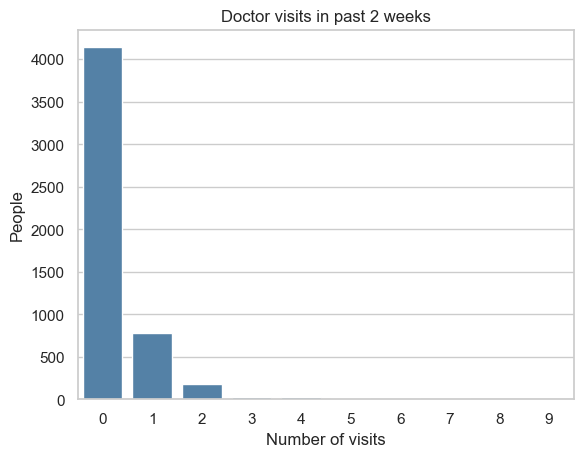

79.8 % had 0 visits


In [11]:
sns.countplot(x='visits', data=df, color='steelblue')
plt.title('Doctor visits in past 2 weeks')
plt.xlabel('Number of visits')
plt.ylabel('People')
plt.show()

print(np.round((df['visits'] == 0).mean() * 100, 1), '% had 0 visits')

### Count of people by number of illnesses in the past 2 weeks

In [31]:
df["illness"].value_counts()

illness
1    1638
0    1554
2     946
3     542
4     274
5     236
Name: count, dtype: int64

### Count of males and females in the data

In [32]:
df["gender"].value_counts()

gender
female    2702
male      2488
Name: count, dtype: int64

### Boxplot to check the spread and outliers in income

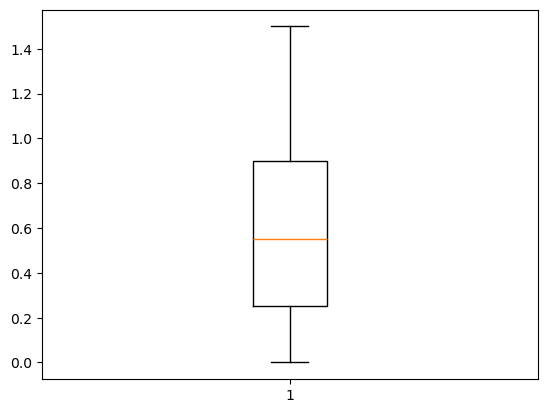

In [33]:
y=list(df.income)
plt.boxplot(y)
plt.show()

### Average of all numeric columns, grouped by gender and reduced-activity days

In [36]:
df.groupby(['gender','reduced']).mean(numeric_only=True)

Unnamed: 0    visits       age    income   illness    health
gender reduced                                                               
female 0        2524.038512  0.229322  0.465755  0.482735  1.462144  1.115098
       1        1985.768421  0.400000  0.325684  0.542105  2.242105  1.610526
       2        1622.618182  0.672727  0.391455  0.560182  2.236364  1.781818
       3         997.311111  1.333333  0.403111  0.516000  2.733333  1.733333
       4        1237.740741  0.851852  0.458889  0.466667  2.222222  2.074074
       5        1169.055556  1.444444  0.401667  0.614444  2.222222  2.500000
       6        1382.545455  1.363636  0.426364  0.622727  2.363636  1.363636
       7        1034.846154  1.384615  0.436154  0.473462  2.653846  2.230769
       8        1883.090909  1.090909  0.471818  0.404545  2.181818  4.000000
       9        1349.000000  0.500000  0.570000  0.825000  3.000000  1.000000
       10       1099.428571  2.142857  0.512857  0.421429  2.571429  2.000000
       12       1661.000000  2.000000  0.720000  0.250000  3.500000  5.500000
       13        906.000000  4.000000  0.720000  0.300000  4.500000  3.500000
       14       1392.112069  1.543103  0.551724  0.427586  2.534483  4.112069
male   0        3008.911019  0.136007  0.344703  0.694398  1.099585  0.924850
       1        2485.158537  0.304878  0.286220  0.676341  1.743902  1.256098
       2        2007.679245  0.471698  0.343585  0.653019  2.358491  1.547170
       3        1909.068966  0.724138  0.334138  0.741379  2.137931  1.689655
       4        1424.000000  0.722222  0.309444  0.869444  2.055556  2.000000
       5        1437.272727  1.136364  0.331818  0.570455  2.272727  2.818182
       6         562.000000  0.833333  0.340000  0.591667  2.500000  2.000000
       7        1716.750000  0.750000  0.314167  0.655000  2.583333  4.333333
       8         680.666667  1.333333  0.365000  0.833333  2.666667  2.000000
       9        1375.400000  2.200000  0.310000  0.392000  2.400000  2.000000
       10       1543.200000  1.800000  0.480000  0.590000  2.600000  4.600000
       11        355.500000  5.000000  0.320000  1.000000  1.500000  0.500000
       12        781.500000  2.000000  0.370000  0.515000  1.500000  1.000000
       13        508.666667  4.000000  0.510000  0.350000  3.333333  2.333333
       14       1236.069444  1.555556  0.476806  0.598611  2.375000  3.527778

### Heatmap of missing values: a single colour means there are no missing values

<Axes: >

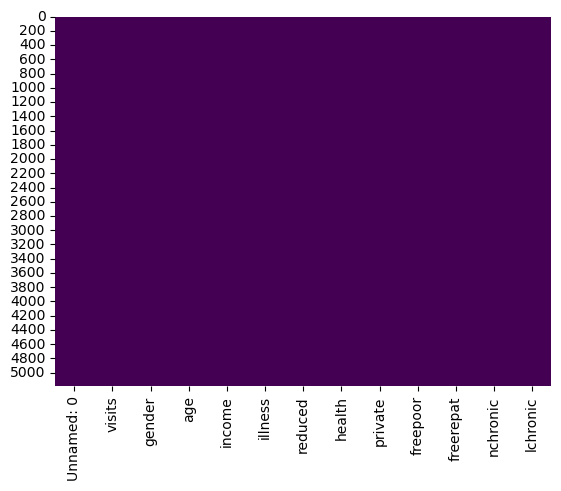

In [37]:
sns.heatmap(df.isnull(),cbar=False,cmap='viridis')

### Correlation matrix of all numeric columns
### Insight: 'reduced' (0.42) and 'illness' (0.22) have the strongest link with visits

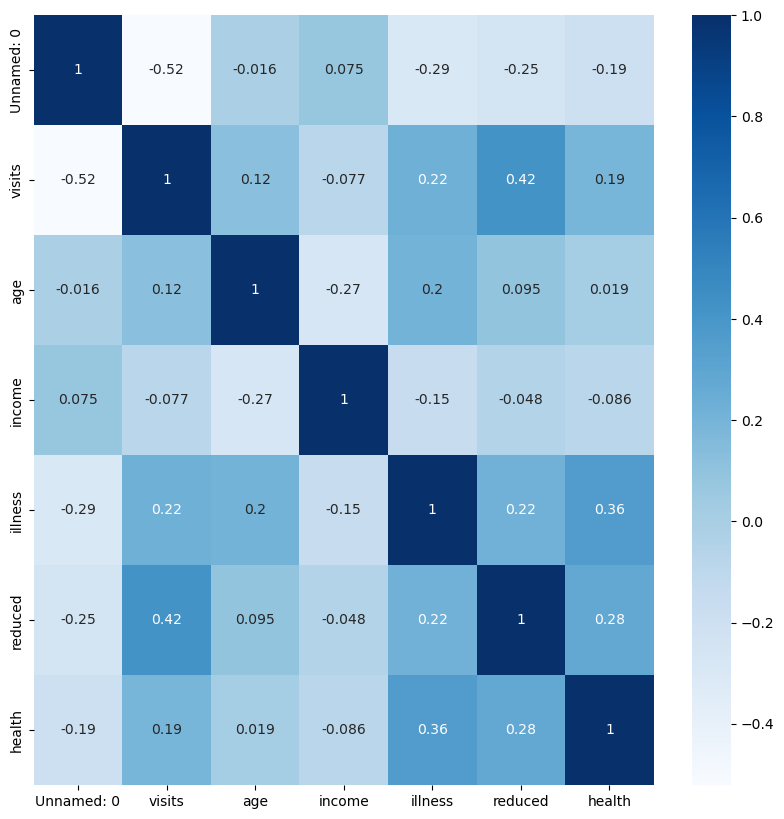

In [41]:
plt.figure(figsize=(10,10))
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    cbar=True,
    annot=True,
    cmap='Blues'
)
plt.show()

### Scatter plot of income vs visits
### Insight: no clear pattern, income has almost no relation with visits (-0.08)

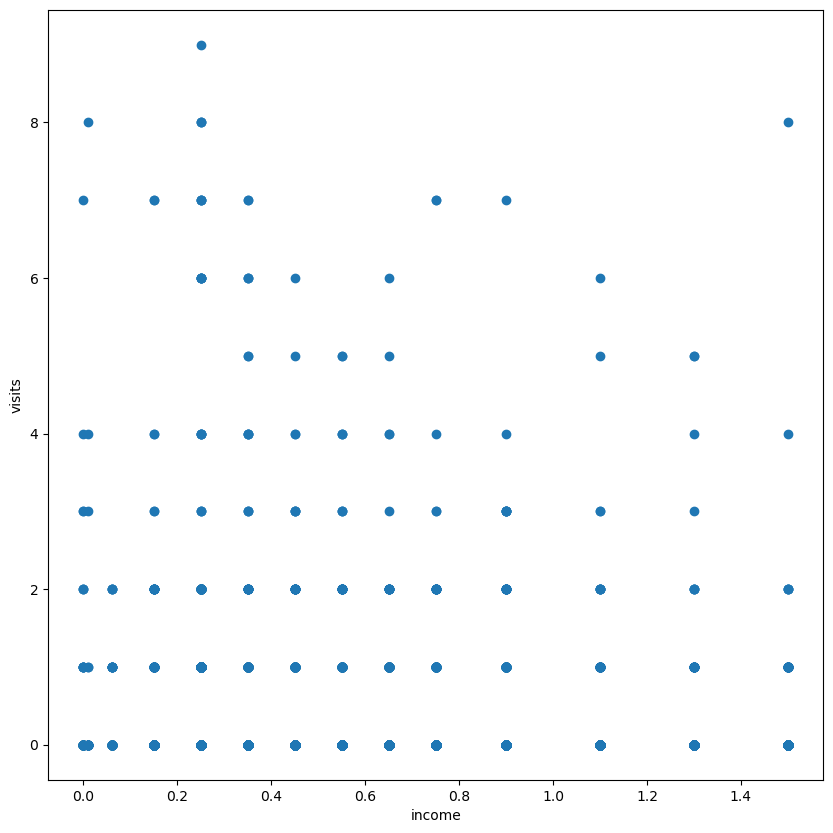

In [42]:
plt.figure(figsize=(10,10))
plt.scatter(x='income',y='visits',data=df)
plt.xlabel('income')
plt.ylabel('visits')
plt.show()

### Age distribution of people in the survey

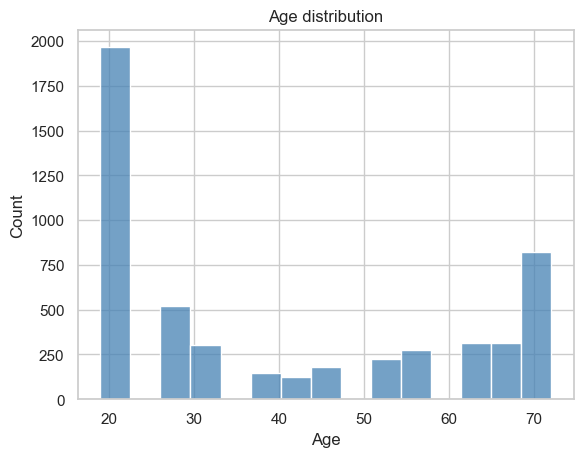

In [12]:
sns.histplot(df['age'], bins=15, color='steelblue')
plt.title('Age distribution')
plt.xlabel('Age')
plt.show()

### Average visits by gender
### Insight: females visit more than males (about 0.36 vs 0.24)

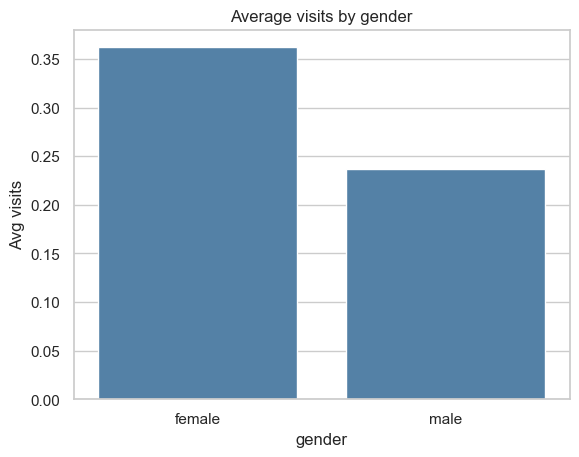

In [13]:
sns.barplot(x='gender', y='visits', data=df, errorbar=None, color='steelblue')
plt.title('Average visits by gender')
plt.ylabel('Avg visits')
plt.show()

### Average visits by age group
### Insight: visits rise with age, 60+ (0.43) visit about twice as much as under 20 (0.21)

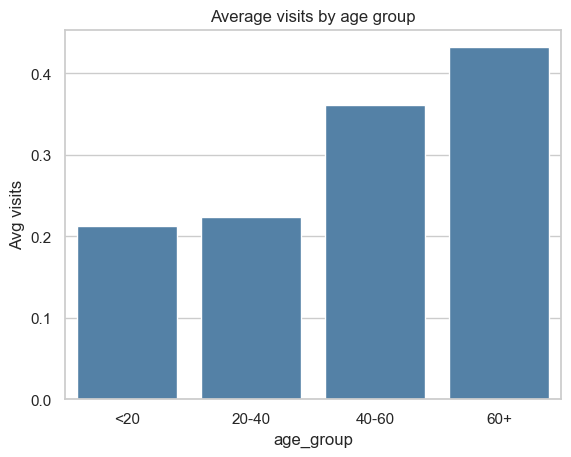

In [14]:
sns.barplot(x='age_group', y='visits', data=df, errorbar=None, color='steelblue')
plt.title('Average visits by age group')
plt.ylabel('Avg visits')
plt.show()

### Average visits by age group
### Insight: visits rise with age, 60+ (0.43) visit about twice as much as under 20 (0.21)

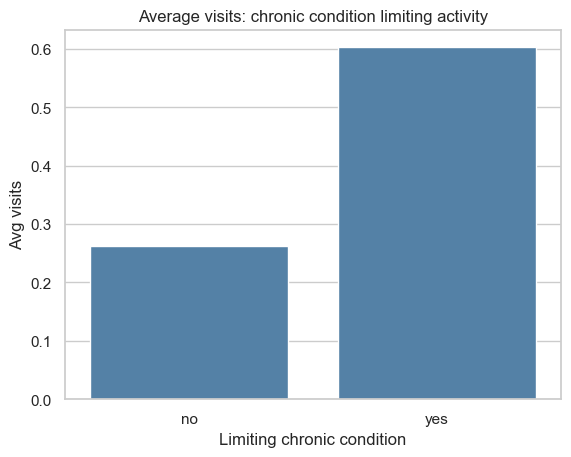

In [15]:
sns.barplot(x='lchronic', y='visits', data=df, errorbar=None, color='steelblue')
plt.title('Average visits: chronic condition limiting activity')
plt.xlabel('Limiting chronic condition')
plt.ylabel('Avg visits')
plt.show()

### Average visits by number of illnesses in the past 2 weeks
### Insight: more illnesses means more visits (0.08 with none, 0.81 with five)

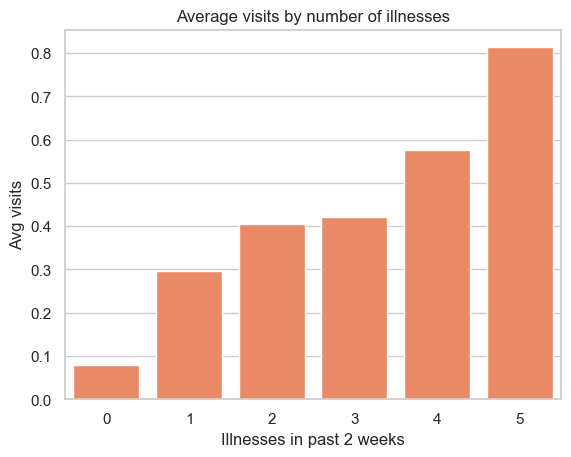

In [16]:
sns.barplot(x='illness', y='visits', data=df, errorbar=None, color='coral')
plt.title('Average visits by number of illnesses')
plt.xlabel('Illnesses in past 2 weeks')
plt.ylabel('Avg visits')
plt.show()

### Average visits by insurance type: private, govt (low income), govt (elderly/disabled/veteran)
### Insight: private insurance makes almost no difference; low-income cover holders visit less

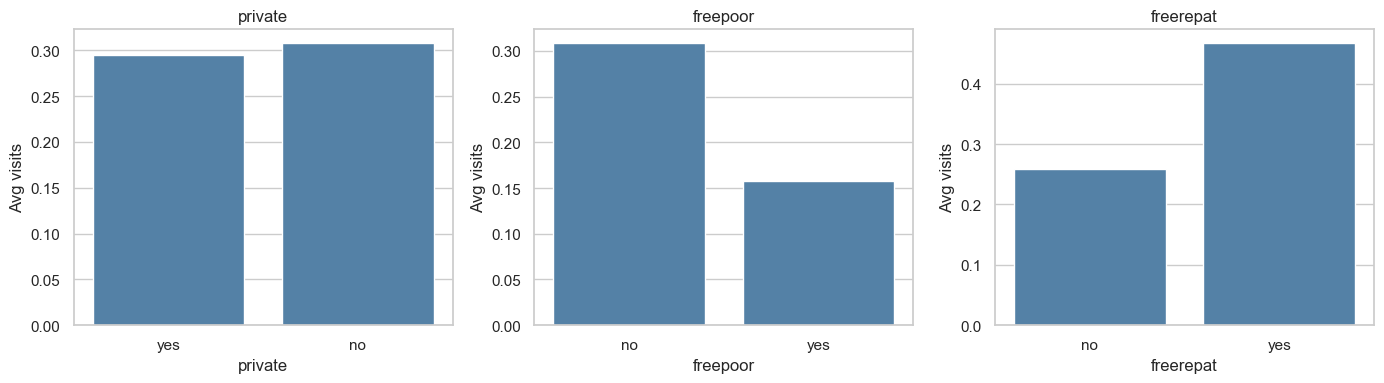

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['private', 'freepoor', 'freerepat']):
    sns.barplot(x=col, y='visits', data=df, errorbar=None, color='steelblue', ax=ax)
    ax.set_title(col)
    ax.set_ylabel('Avg visits')
plt.tight_layout()
plt.show()

### Compare income of people who visited vs did not visit
### Insight: no strong income difference, so income is not a main driver

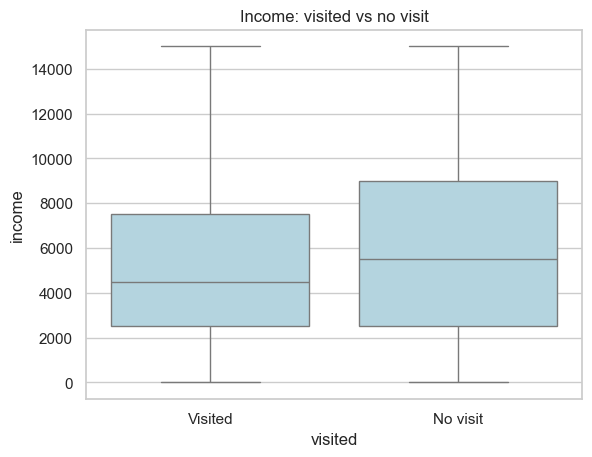

In [18]:
sns.boxplot(x='visited', y='income', data=df, color='lightblue')
plt.title('Income: visited vs no visit')
plt.show()

### Correlation of visits with key health and demographic columns

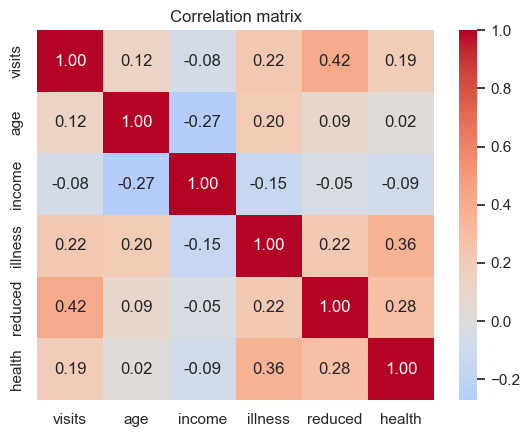

In [19]:
sns.heatmap(df[['visits', 'age', 'income', 'illness', 'reduced', 'health']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

# Pie charts showing the share of people in each insurance group (yes vs no)

#### Visualizing the percentage of people getting govt health insurance due to low income,due to old age and also the percentage of people having private health insurance

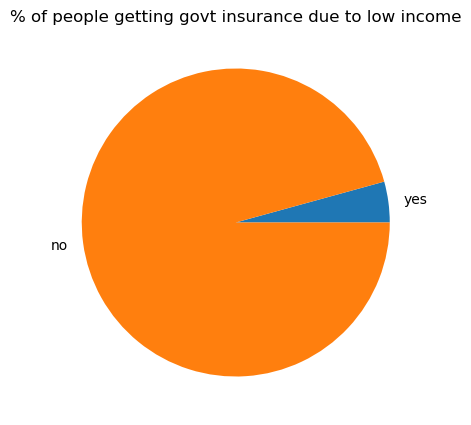

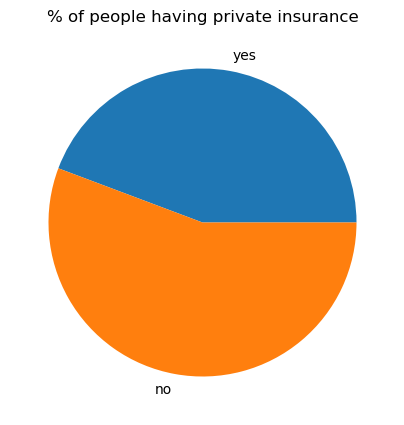

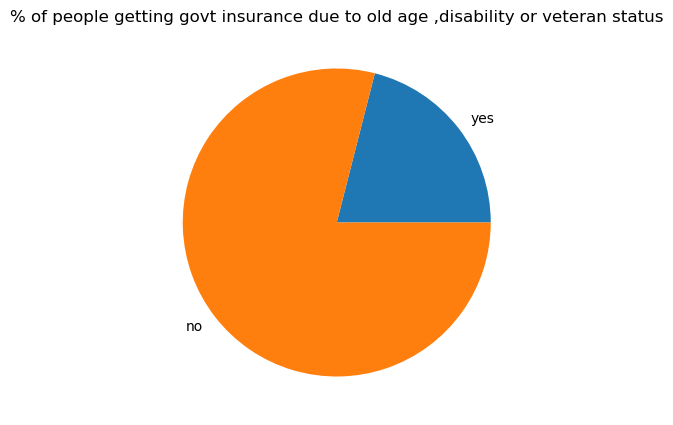

In [49]:
# % of people getting govt insurance due to low income
label=['yes','no']
Y=df[df['freepoor']=='yes']
N=df[df['freepoor']=='no']
x=[Y.shape[0],N.shape[0]]
plt.figure(figsize=(5,5))
plt.pie(x,labels=label)
plt.title("% of people getting govt insurance due to low income")
plt.show()

# % of people having private insurance
Y=df[df['private']=='yes']
N=df[df['private']=='no']
x=[Y.shape[0],N.shape[0]]
plt.figure(figsize=(5,5))
plt.pie(x,labels=label)
plt.title("% of people having private insurance")
plt.show()

# % of people getting govt insurance due to old age ,disability or veteran status
Y=df[df['freerepat']=='yes']
N=df[df['freerepat']=='no']
x=[Y.shape[0],N.shape[0]]
plt.figure(figsize=(5,5))
plt.pie(x,labels=label)
plt.title("% of people getting govt insurance due to old age ,disability or veteran status")
plt.show()


### Total reduced-activity days by gender (horizontal bar chart)

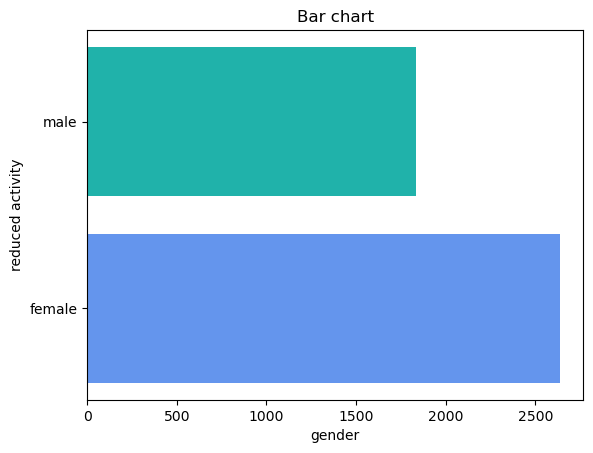

In [52]:
db=df.groupby('gender')['reduced'].sum().to_frame().reset_index()
plt.barh(db['gender'],db['reduced'],color=['cornflowerblue','lightseagreen'])
plt.title('Bar chart')
plt.xlabel('gender')
plt.ylabel('reduced activity')
plt.show()

In [20]:
df.to_csv('DoctorVisits_clean.csv', index=False)

# Conclusion
## Health need (illness, chronic conditions, reduced-activity days) drives doctor visits the most.
## Age and gender matter too. Income and private insurance matter very little.